# EUR and PPS income comparison

We compare published median equivalised disposable income (`MED_EI`, `sex=T`, `age=TOTAL`) in EUR and PPS.

The API retrieval covers survey years 2003–2025 and a fixed set of 37 countries from the Streamlit catalogue. All 851 country-year rows, missing values and complete flag strings are retained. No imputation is applied.

Only 2018 has complete paired coverage of all 37 countries in this retrieval. Ranks remain missing in other years.

Rank 1 represents the highest income. Competition ranking handles ties as `1, 2, 2, 4`. We define `rank_change = rank_EUR - rank_PPS`: positive values indicate a higher position with PPS.

PPS adjusts for national price-level differences; it is not a constant-price series for measuring real income growth. Years remain survey years, since income reference periods can differ across countries and historical periods.

The source JSON records the API query, retrieval time, filters and provider metadata. Future API revisions may change the results.

Definitions:
- [Eurostat: Purchasing power standard](https://ec.europa.eu/eurostat/statistics-explained/index.php?title=Glossary:Purchasing_power_standard_(PPS))
- [Eurostat: PPP comparisons across years](https://ec.europa.eu/eurostat/en/web/purchasing-power-parities/information-data)
- [Eurostat: EU-SILC reference metadata](https://ec.europa.eu/eurostat/cache/metadata/en/ilc_sieusilc.htm)

In [1]:
from pathlib import Path
import sys
import pandas as pd
import json
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

In [2]:
notebook_dir = Path.cwd()
project_dir = notebook_dir.parent

print("Python:", sys.version.split()[0])
print("Executable:", sys.executable)
print("Working directory:", notebook_dir)
print("pandas:", pd.__version__)

Python: 3.13.17
Executable: c:\Users\georg\miniconda3\envs\eurostat-income-repro\python.exe
Working directory: c:\Users\georg\bigblue_academy\git_hub\eurostat-income-analysis\notebooks
pandas: 3.1.0


In [3]:
# Relative paths must start from the notebooks directory.
assert notebook_dir.name == "notebooks", ("The working directory must be notebooks/.")

assert (project_dir / "eurostat_api.py").is_file(), ("The project API module was not found.")

print("Notebook location check: OK")

Notebook location check: OK


In [4]:
# Allow imports from the repository root.
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from eurostat_api import fetch_income_catalogue

catalogue = fetch_income_catalogue()

In [5]:
# Match Streamlit's country options across the entire catalogue.
available_catalogue = catalogue.loc[catalogue["value"].notna()].copy()

In [6]:
# Extract unique country labels, without removing observation records.
country_table = (
    available_catalogue[["geo", "geo_label"]]
    .drop_duplicates()
    .sort_values("geo_label")
    .reset_index(drop=True))

assert country_table["geo"].is_unique, "Conflicting country labels."
assert "EL" in country_table["geo"].values, "Greece is missing."

In [7]:
# Use this same country list for every survey year.
fixed_countries = tuple(country_table["geo"])

start_year = 2003
end_year = int(available_catalogue["time"].astype(int).max())

print("Number of countries:", len(fixed_countries))
print("Fixed country codes:", ", ".join(fixed_countries))
print("Catalogue survey years:", start_year, "-", end_year)
print("Retrieved at UTC:", catalogue.attrs["retrieved_at_utc"])
print("API request:", catalogue.attrs["request_url"])

display(country_table)

Number of countries: 37
Fixed country codes: AL, AT, BE, BG, HR, CY, CZ, DK, EE, FI, FR, DE, EL, HU, IS, IE, IT, XK, LV, LT, LU, MT, ME, NL, MK, NO, PL, PT, RO, RS, SK, SI, ES, SE, CH, TR, UK
Catalogue survey years: 2003 - 2025
Retrieved at UTC: 2026-11-05T20:11:01+00:00
API request: https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/ilc_di03?lang=EN&freq=A&age=TOTAL&sex=T&geoLevel=country&sinceTimePeriod=2003


,geo,geo_label
0,AL,Albania
1,AT,Austria
2,BE,Belgium
3,BG,Bulgaria
4,HR,Croatia
5,CY,Cyprus
6,CZ,Czechia
7,DK,Denmark
8,EE,Estonia
9,FI,Finland


In [8]:
# Select median income, total population, and the two comparison units.
income_data = catalogue.loc[
    catalogue["statinfo"].eq("MED_EI")
    & catalogue["age"].eq("TOTAL")
    & catalogue["sex"].eq("T")
    & catalogue["freq"].eq("A")
    & catalogue["unit"].isin(["EUR", "PPS"])
    & catalogue["geo"].isin(fixed_countries)
].copy()

income_data["survey_year"] = income_data["time"].astype(int)

In [9]:
# Check observation keys before reshaping.
key = ["geo", "survey_year", "unit"]

assert not income_data[key].isna().any().any(), "Missing observation keys."
assert not income_data.duplicated(key).any(), "Duplicate observation keys."
assert income_data["survey_year"].between(start_year, end_year).all()

# Include every fixed country in every survey year.
full_index = pd.MultiIndex.from_product(
    [fixed_countries, range(start_year, end_year + 1)],
    names=["geo", "survey_year"])

paired_values = income_data.pivot(
    index=["geo", "survey_year"],
    columns="unit",
    values="value",
).reindex(index=full_index, columns=["EUR", "PPS"])

In [10]:
# Count available values and complete EUR/PPS pairs.
availability = paired_values.notna()

coverage = (
    availability.groupby(level="survey_year")
    .sum()
    .rename(columns={
        "EUR": "EUR_available",
        "PPS": "PPS_available"}))

coverage["paired_available"] = (
    availability.all(axis=1)
    .groupby(level="survey_year")
    .sum())

coverage.insert(0, "countries_expected", len(fixed_countries))
coverage["missing_pairs"] = (coverage["countries_expected"] - coverage["paired_available"])

complete_years = coverage.index[coverage["missing_pairs"].eq(0)].tolist()

display(coverage)
print("Years with complete paired coverage:", complete_years)

unit,countries_expected,EUR_available,PPS_available,paired_available,missing_pairs
survey_year,,,,,
2003,37,7,7,7,30
2004,37,15,15,15,22
2005,37,27,27,27,10
2006,37,29,29,29,8
2007,37,31,31,31,6
2008,37,31,31,31,6
2009,37,31,31,31,6
2010,37,32,32,32,5
2011,37,32,32,32,5


Years with complete paired coverage: [2018]


In [11]:
# Summarise paired coverage for each fixed country.
paired_ok = paired_values.notna().all(axis=1)

country_coverage = country_table.set_index("geo").copy()

country_coverage["paired_years"] = (paired_ok.groupby(level="geo").sum())

country_coverage["missing_years_count"] = (end_year - start_year + 1 - country_coverage["paired_years"])

missing_country_years = (paired_values.loc[~paired_ok].reset_index()[["geo", "survey_year"]])

missing_years_by_country = (missing_country_years.groupby("geo")["survey_year"].agg(list))

country_coverage["missing_years"] = [missing_years_by_country.get(code, []) for code in country_coverage.index]

In [12]:
# Preserve complete flag strings and count flagged rows by unit.
flagged_observations = income_data.loc[
    income_data["obs_flag"].fillna("").ne(""),
    ["geo", "geo_label", "survey_year", "unit", "value", "obs_flag"]
].copy()

flag_summary = (
    flagged_observations.groupby(["unit", "obs_flag"])
    .size()
    .reset_index(name="flagged_rows"))

print("Coverage by country:")
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(country_coverage.reset_index())

print("Flag summary across all survey years:")
display(flag_summary)

Coverage by country:


,geo,geo_label,paired_years,missing_years_count,missing_years
0,AL,Albania,9,14,"[2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016]"
1,AT,Austria,23,0,[]
2,BE,Belgium,23,0,[]
3,BG,Bulgaria,20,3,"[2003, 2004, 2005]"
4,HR,Croatia,16,7,"[2003, 2004, 2005, 2006, 2007, 2008, 2009]"
5,CY,Cyprus,21,2,"[2003, 2004]"
6,CZ,Czechia,21,2,"[2003, 2004]"
7,DK,Denmark,23,0,[]
8,EE,Estonia,22,1,[2003]
9,FI,Finland,22,1,[2003]


Flag summary across all survey years:


,unit,obs_flag,flagged_rows
0,EUR,b,44
1,EUR,p,2
2,PPS,b,44
3,PPS,p,2


In [13]:
# Align the original flags with the country-year income pairs.
paired_flags = income_data.pivot(
    index=["geo", "survey_year"],
    columns="unit",
    values="obs_flag",
).reindex(index=paired_values.index, columns=["EUR", "PPS"])

comparison = (
    paired_values
    .rename(columns={"EUR": "median_EUR", "PPS": "median_PPS"})
    .join(paired_flags.add_prefix("flag_"), validate="one_to_one")
    .reset_index()
    .rename(columns={"geo": "geo_code"}))

comparison.columns.name = None

country_names = country_table.set_index("geo")["geo_label"]
comparison["geo_name"] = comparison["geo_code"].map(country_names)

comparison["pair_complete"] = (comparison[["median_EUR", "median_PPS"]].notna().all(axis=1))

In [14]:
# Rank only years with complete coverage of all fixed countries.
rankable = comparison["survey_year"].isin(complete_years)

ranks = (
    comparison.loc[rankable]
    .groupby("survey_year")[["median_EUR", "median_PPS"]]
    .rank(method="min", ascending=False)
    .rename(columns={
        "median_EUR": "rank_EUR",
        "median_PPS": "rank_PPS",
    })
    .astype("Int64"))

In [15]:
# Other years retain their income values and flags, with missing ranks.
comparison = comparison.join(ranks, validate="one_to_one")
comparison["rank_change"] = (comparison["rank_EUR"] - comparison["rank_PPS"])

comparison = comparison[[
    "geo_code", "geo_name", "survey_year",
    "median_EUR", "median_PPS",
    "flag_EUR", "flag_PPS", "pair_complete",
    "rank_EUR", "rank_PPS", "rank_change"]]

print("Country-year rows:", len(comparison))
print("Ranked survey years:", complete_years)

display(comparison.loc[rankable].sort_values(["survey_year", "rank_EUR", "geo_name"]))

Country-year rows: 851
Ranked survey years: [2018]


,geo_code,geo_name,survey_year,median_EUR,median_PPS,flag_EUR,flag_PPS,pair_complete,rank_EUR,rank_PPS,rank_change
797,CH,Switzerland,2018,43013.0,27066.0,<NA>,<NA>,True,1,2,-1
337,IS,Iceland,2018,39918.0,23667.0,<NA>,<NA>,True,2,4,-2
590,NO,Norway,2018,39438.0,26300.0,<NA>,<NA>,True,3,3,0
475,LU,Luxembourg,2018,34472.0,27529.0,<NA>,<NA>,True,4,1,3
176,DK,Denmark,2018,30104.0,21646.0,<NA>,<NA>,True,5,7,-2
774,SE,Sweden,2018,25540.0,20414.0,<NA>,<NA>,True,6,10,-4
38,AT,Austria,2018,25176.0,23204.0,<NA>,<NA>,True,7,5,2
360,IE,Ireland,2018,24920.0,19464.0,<NA>,<NA>,True,8,13,-5
222,FI,Finland,2018,24544.0,20048.0,<NA>,<NA>,True,9,12,-3
544,NL,Netherlands,2018,24016.0,21528.0,<NA>,<NA>,True,10,8,2


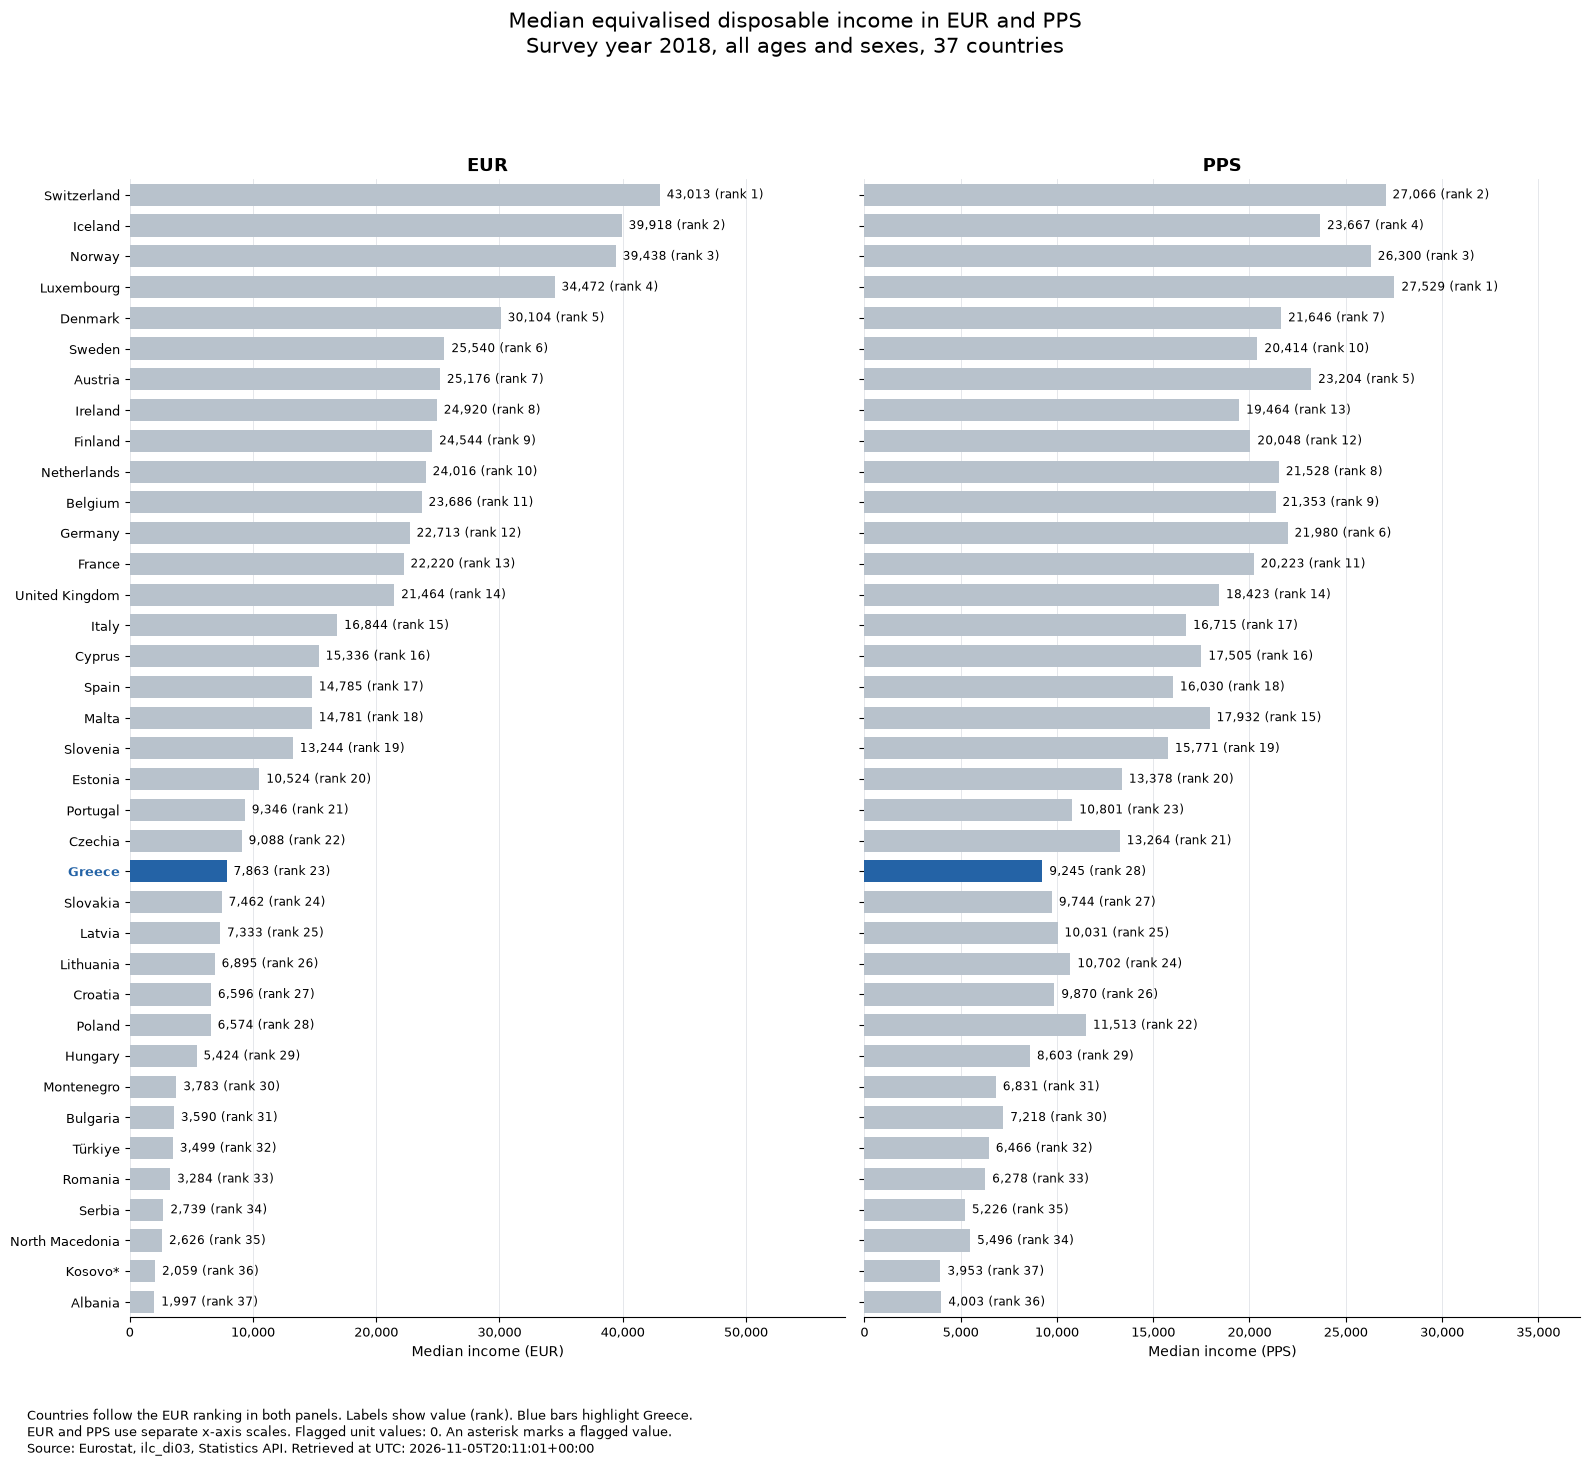

In [16]:
plot_year = 2018
assert plot_year in complete_years, "Select a year with full country coverage."

plot_data = (
    comparison.loc[comparison["survey_year"].eq(plot_year)]
    .sort_values("median_EUR", ascending=False)
    .reset_index(drop=True))

assert len(plot_data) == len(fixed_countries)

positions = range(len(plot_data))
colors = [
    "#2463A6" if code == "EL" else "#B8C2CC"
    for code in plot_data["geo_code"]]

eur_pps_fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 15),
    sharey=True,
    sharex=False,
    facecolor="white")

for ax, unit in zip(axes, ["EUR", "PPS"]):
    value_col = f"median_{unit}"
    rank_col = f"rank_{unit}"
    flagged = plot_data[f"flag_{unit}"].fillna("").ne("")

    bars = ax.barh(
        positions,
        plot_data[value_col],
        color=colors,
        height=0.72)

    # Labels show the published value and its rank within the same unit.
    labels = [
        f"{value:,.0f} (rank {rank})" + (" *" if marked else "")
        for value, rank, marked in zip(
            plot_data[value_col], plot_data[rank_col], flagged
        )
    ]
    ax.bar_label(bars, labels=labels, padding=5, fontsize=8.5)

    # Leave room for labels; each panel has its own numerical scale.
    ax.set_xlim(0, plot_data[value_col].max() * 1.35)
    ax.set_title(unit, fontsize=13, fontweight="bold")
    ax.set_xlabel(f"Median income ({unit})", fontsize=10)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.tick_params(axis="both", labelsize=9)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#E5E7EB", linewidth=0.7)

    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)

axes[0].set_yticks(positions, labels=plot_data["geo_name"])

# Reverse the shared country axis once, for both panels.
axes[0].set_ylim(len(plot_data) - 0.5, -0.5)

for label in axes[0].get_yticklabels():
    if label.get_text() == "Greece":
        label.set_color("#2463A6")
        label.set_fontweight("bold")

flag_total = int(
    plot_data[["flag_EUR", "flag_PPS"]]
    .fillna("").ne("").sum().sum())

eur_pps_fig.suptitle(
    "Median equivalised disposable income in EUR and PPS\n"
    f"Survey year {plot_year}, all ages and sexes, "
    f"{len(plot_data)} countries",
    fontsize=15,
    y=0.985)

eur_pps_fig.text(
    0.02, 0.02,
    "Countries follow the EUR ranking in both panels. "
    "Labels show value (rank). Blue bars highlight Greece.\n"
    "EUR and PPS use separate x-axis scales. "
    f"Flagged unit values: {flag_total}. An asterisk marks a flagged value.\n"
    "Source: Eurostat, ilc_di03, Statistics API. "
    f"Retrieved at UTC: {catalogue.attrs['retrieved_at_utc']}",
    fontsize=9,
    ha="left",
    va="bottom")

eur_pps_fig.tight_layout(rect=(0, 0.075, 1, 0.94))
plt.show()

## Findings for survey year 2018

- Greece ranks 23rd in EUR (€7,863) and 28th in PPS (9,245 PPS), placing five positions lower in the PPS ranking.
- Slovakia, Latvia, Lithuania, Croatia and Poland rank below Greece in EUR but above it in PPS.
- Germany and Poland each rank six positions higher with PPS. Luxembourg moves from fourth in EUR to first in PPS.
- Some positions remain unchanged: Norway ranks third and the United Kingdom ranks 14th in both units.
- These are descriptive comparisons within the same survey year. They do not measure income growth over time or establish statistical significance, causality or overall quality of life.

In [17]:
processed_dir = project_dir / "data" / "processed"
figures_dir = project_dir / "reports" / "figures"

processed_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

all_years_path = (processed_dir / f"eur_pps_comparison_{start_year}_{end_year}.csv")
selected_year_path = (processed_dir / f"eur_pps_comparison_{plot_year}.csv")
figure_path = figures_dir / f"eur_pps_comparison_{plot_year}.png"
source_path = (processed_dir / f"eur_pps_source_{start_year}_{end_year}.json")

In [18]:
# Export all country-years, including missing values and unavailable ranks.
comparison.sort_values(
    ["survey_year", "geo_name"]
).to_csv(
    all_years_path,
    index=False,
    encoding="utf-8",
    na_rep="")

comparison.loc[
    comparison["survey_year"].eq(plot_year)
].sort_values(
    ["rank_EUR", "geo_name"]
).to_csv(
    selected_year_path,
    index=False,
    encoding="utf-8",
    na_rep="")

In [19]:
# Save the displayed Figure object directly.
eur_pps_fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
    facecolor="white")

In [20]:
# Record provenance for the API response used in this execution.
source_record = {
    "dataset": "ilc_di03",
    "request_url": catalogue.attrs["request_url"],
    "retrieved_at_utc": catalogue.attrs["retrieved_at_utc"],
    "survey_year_start": start_year,
    "survey_year_end": end_year,
    "fixed_countries": list(fixed_countries),
    "filters": {
        "freq": "A",
        "age": "TOTAL",
        "sex": "T",
        "statinfo": "MED_EI",
        "units": ["EUR", "PPS"],
    },
    "ranking_years": complete_years,
    "rank_method": "Competition ranking: min, descending",
    "rank_change_definition": "rank_EUR - rank_PPS",
    "eurostat_metadata": catalogue.attrs["eurostat_metadata"]}

with source_path.open("w", encoding="utf-8") as file:
    json.dump(source_record, file, ensure_ascii=False, indent=2)

for output_path in [
    all_years_path, selected_year_path, figure_path, source_path
]:
    print("Saved:", output_path.relative_to(project_dir))

Saved: data\processed\eur_pps_comparison_2003_2025.csv
Saved: data\processed\eur_pps_comparison_2018.csv
Saved: reports\figures\eur_pps_comparison_2018.png
Saved: data\processed\eur_pps_source_2003_2025.json
